<a href="https://colab.research.google.com/github/JonerciJon/CSST106/blob/main/Lab%207%20Experiment%20Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload an image (JPG/PNG), or cancel to generate a synthetic multi-object scene:


Saving 41.jpg to 41.jpg
Loaded '41.jpg' with shape (736, 736, 3)
[Thresholding] Otsu optimal threshold: 136.0
[Region-Based] Seed=(161, 264), grown pixels=56078
[Edge-Based] Canny contours found=34, significant=1
Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 132MB/s]


[Semantic] Fallback region map (DeepLab unavailable: error)


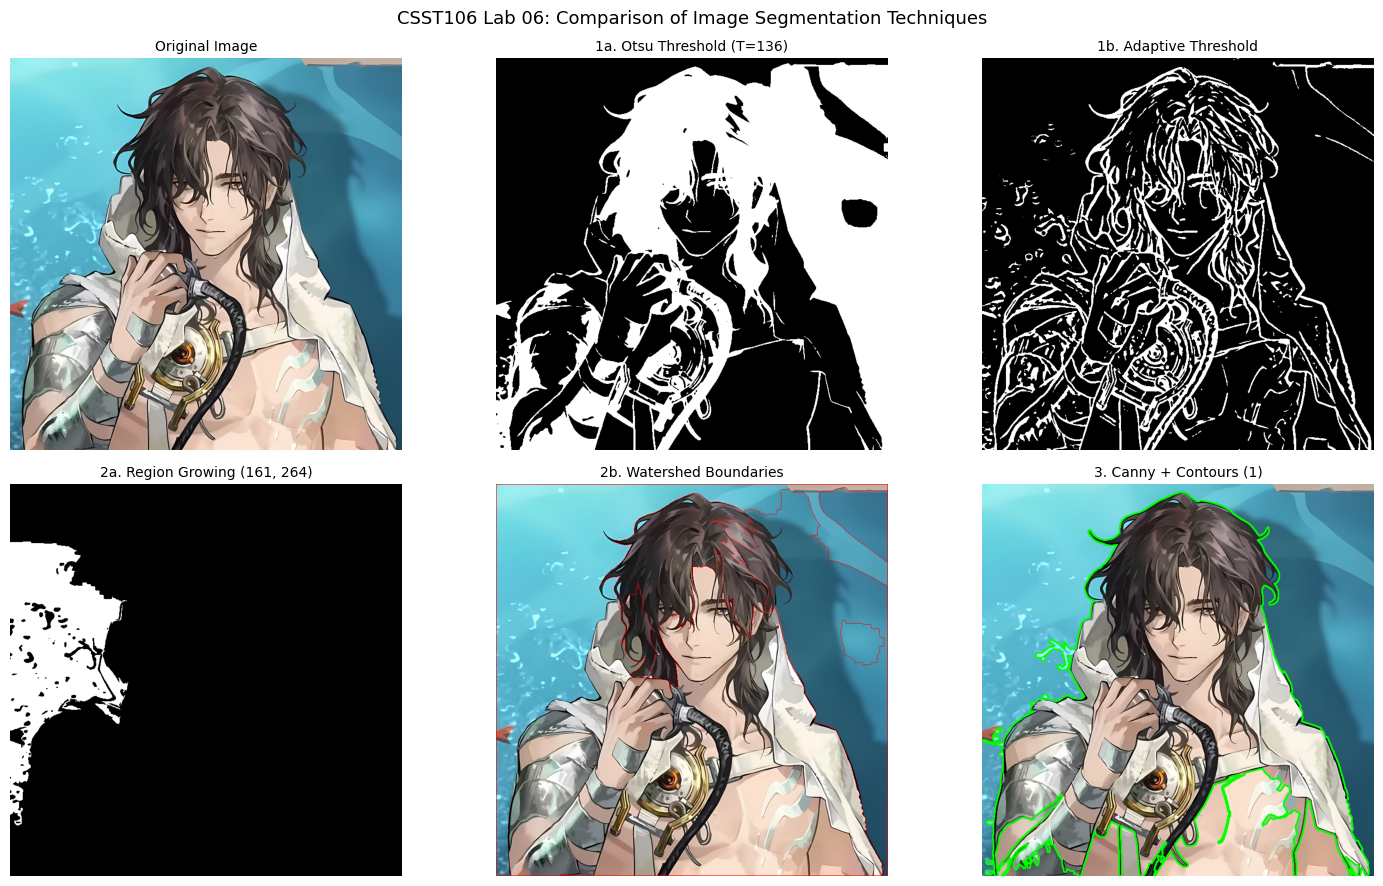

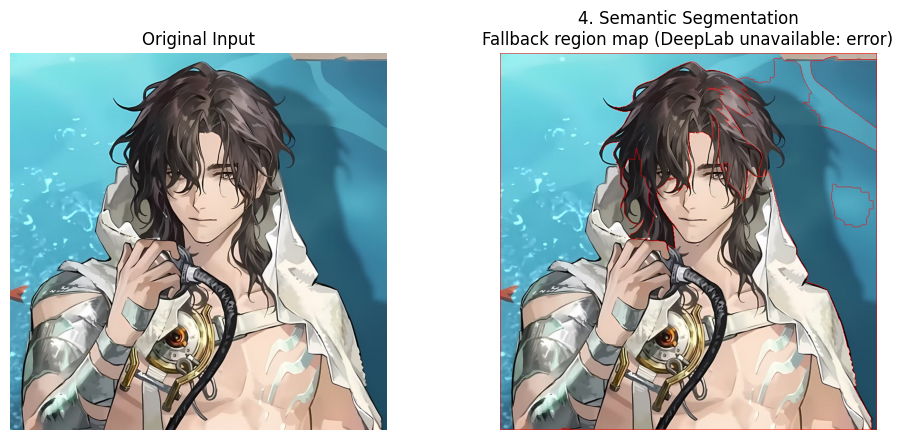


Sample IoU (Otsu vs. Adaptive mask): 0.2910


In [4]:
# ==============================================================================
# CSST106 - Laboratory Exercise No. 6: Image Segmentation Techniques
# Colab-compatible script covering:
#   1. Thresholding (Otsu & Adaptive Thresholding)
#   2. Region-Based (Region Growing & Watershed)
#   3. Edge-Based (Canny Edges & Contour Segmentation)
#   4. Semantic Segmentation (DeepLabV3 / PyTorch + fallback)
# ==============================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


def load_or_create_scene():
    """Upload a natural/object image in Colab or generate a multi-object test scene."""
    print("Upload an image (JPG/PNG), or cancel to generate a synthetic multi-object scene:")
    try:
        uploaded = files.upload()
        if uploaded:
            fname = next(iter(uploaded))
            img_bgr = cv2.imread(fname)
            if img_bgr is not None:
                return img_bgr, fname
    except Exception:
        pass

    print("No file uploaded; generating a synthetic scene with uneven lighting & touching objects...")
    h, w = 360, 480
    # Create uneven illumination gradient (left brighter, right darker)
    x_grad = np.tile(np.linspace(1.15, 0.55, w, dtype=np.float32), (h, 1))
    bg = np.clip(180 * x_grad, 0, 255).astype(np.uint8)
    scene_bgr = cv2.cvtColor(bg, cv2.COLOR_GRAY2BGR)

    # Object 1: Dark rectangle on left
    cv2.rectangle(scene_bgr, (45, 70), (165, 190), (45, 45, 55), -1)

    # Touching / overlapping circles on right (great for Watershed separation)
    cv2.circle(scene_bgr, (295, 175), 55, (70, 95, 130), -1)
    cv2.circle(scene_bgr, (375, 195), 50, (90, 120, 150), -1)

    # Object 3: Bright/distinct shape near bottom
    cv2.ellipse(scene_bgr, (130, 285), (65, 35), 0, 0, 360, (225, 225, 225), -1)

    rng = np.random.default_rng(42)
    noise = rng.normal(0, 5, scene_bgr.shape).astype(np.int16)
    scene_bgr = np.clip(scene_bgr.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    cv2.imwrite("segmentation_sample.jpg", scene_bgr)
    return scene_bgr, "segmentation_sample.jpg"


def compute_iou(pred_mask, gt_mask):
    """Compute Intersection over Union (IoU) between two binary masks."""
    p = pred_mask.astype(bool)
    g = gt_mask.astype(bool)
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    return float(inter / union) if union > 0 else 0.0


# ==============================================================================
# LOAD IMAGE & PREPROCESS
# ==============================================================================
img_bgr, filename = load_or_create_scene()
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
h, w = gray.shape
print(f"Loaded '{filename}' with shape {img_bgr.shape}")


# ==============================================================================
# 1. THRESHOLDING SEGMENTATION (Otsu's Global & Adaptive)
# ==============================================================================
blur_gray = cv2.GaussianBlur(gray, (5, 5), 0)

# Otsu's global thresholding (automatically finds optimal threshold)
otsu_thresh, otsu_mask = cv2.threshold(
    blur_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Adaptive thresholding (handles uneven/non-uniform lighting)
adaptive_mask = cv2.adaptiveThreshold(
    blur_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV, blockSize=25, C=7
)
print(f"[Thresholding] Otsu optimal threshold: {otsu_thresh:.1f}")


# ==============================================================================
# 2. REGION-BASED SEGMENTATION (Region Growing & Watershed)
# ==============================================================================
def region_growing(gray_img, seed_xy, tolerance=18):
    """Simple BFS region growing starting at (x, y) using intensity similarity."""
    rows, cols = gray_img.shape
    visited = np.zeros((rows, cols), dtype=bool)
    mask = np.zeros((rows, cols), dtype=np.uint8)

    sx, sy = seed_xy
    sx = int(np.clip(sx, 0, cols - 1))
    sy = int(np.clip(sy, 0, rows - 1))
    seed_val = int(gray_img[sy, sx])

    stack = [(sy, sx)]
    visited[sy, sx] = True

    while stack:
        cy, cx = stack.pop()
        if abs(int(gray_img[cy, cx]) - seed_val) <= tolerance:
            mask[cy, cx] = 255
            for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                ny, nx = cy + dy, cx + dx
                if 0 <= ny < rows and 0 <= nx < cols and not visited[ny, nx]:
                    visited[ny, nx] = True
                    stack.append((ny, nx))
    return mask


# Seed point near upper-left-ish dark object (adapts to image size)
seed_pt = (int(w * 0.22), int(h * 0.36))
region_grown_mask = region_growing(blur_gray, seed_pt, tolerance=20)

# Watershed segmentation for separating foreground/touching regions
_, binary_for_ws = cv2.threshold(blur_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(binary_for_ws, cv2.MORPH_OPEN, kernel, iterations=2)

sure_bg = cv2.dilate(opening, kernel, iterations=3)
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist_transform, 0.35 * dist_transform.max(), 255, 0)
sure_fg = sure_fg.astype(np.uint8)
unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

ws_img = img_bgr.copy()
markers_ws = cv2.watershed(ws_img, markers)
watershed_vis = img_rgb.copy()
watershed_vis[markers_ws == -1] = [255, 0, 0]  # Mark watershed boundaries in red
print(f"[Region-Based] Seed={seed_pt}, grown pixels={np.count_nonzero(region_grown_mask)}")


# ==============================================================================
# 3. EDGE-BASED SEGMENTATION (Canny + Closed Contours)
# ==============================================================================
canny_edges = cv2.Canny(blur_gray, threshold1=50, threshold2=150)

# Dilate slightly to connect nearby edge fragments before finding contours
edges_closed = cv2.dilate(canny_edges, np.ones((3, 3), np.uint8), iterations=1)
contours, _ = cv2.findContours(edges_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

contour_overlay = img_rgb.copy()
min_area = (h * w) * 0.005  # Filter tiny noise contours
significant_contours = [c for c in contours if cv2.contourArea(c) >= min_area]
cv2.drawContours(contour_overlay, significant_contours, -1, (0, 255, 0), 2)
print(f"[Edge-Based] Canny contours found={len(contours)}, significant={len(significant_contours)}")


# ==============================================================================
# 4. SEMANTIC SEGMENTATION (DeepLabV3 with PyTorch + Fallback)
# ==============================================================================
semantic_vis = None
semantic_status = ""

try:
    import torch
    from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

    device = "cuda" if torch.cuda.is_available() else "cpu"
    weights = DeepLabV3_ResNet50_Weights.DEFAULT
    model = deeplabv3_resnet50(weights=weights).to(device).eval()
    preprocess = weights.transforms()

    from PIL import Image
    pil_img = Image.fromarray(img_rgb)
    input_tensor = preprocess(pil_img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)["out"][0]
    pred_classes = output.argmax(0).byte().cpu().numpy()

    # Colorize class IDs deterministically
    rng_pal = np.random.default_rng(123)
    palette = rng_pal.integers(0, 255, size=(256, 3), dtype=np.uint8)
    palette[0] = [30, 30, 30]  # Background class 0
    color_mask = palette[pred_classes]
    semantic_vis = cv2.addWeighted(img_rgb, 0.45, color_mask, 0.55, 0)

    unique_ids = np.unique(pred_classes)
    detected_labels = [weights.meta["categories"][idx] for idx in unique_ids if idx < len(weights.meta["categories"])]
    semantic_status = f"DeepLabV3 ({device}): {detected_labels}"
except Exception as e:
    # Fallback superpixel/color-cluster mask if pretrained weights cannot download
    semantic_vis = watershed_vis.copy()
    semantic_status = f"Fallback region map (DeepLab unavailable: {type(e).__name__})"

print(f"[Semantic] {semantic_status}")


# ==============================================================================
# VISUALIZE ALL FOUR SEGMENTATION METHODS SIDE BY SIDE
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle("CSST106 Lab 06: Comparison of Image Segmentation Techniques", fontsize=13)

panels = [
    (img_rgb, "Original Image", None),
    (otsu_mask, f"1a. Otsu Threshold (T={otsu_thresh:.0f})", "gray"),
    (adaptive_mask, "1b. Adaptive Threshold", "gray"),
    (region_grown_mask, f"2a. Region Growing {seed_pt}", "gray"),
    (watershed_vis, "2b. Watershed Boundaries", None),
    (contour_overlay, f"3. Canny + Contours ({len(significant_contours)})", None),
]

for ax, (im, title, cmap) in zip(axes.flat, panels):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.savefig("lab06_classical_segmentation.png", dpi=150)
plt.show()

# Dedicated Semantic Segmentation figure
plt.figure(figsize=(10, 4.5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Input")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(semantic_vis)
plt.title(f"4. Semantic Segmentation\n{semantic_status[:55]}")
plt.axis("off")

plt.tight_layout()
plt.savefig("lab06_semantic_segmentation.png", dpi=150)
plt.show()

# Example IoU calculation comparing Otsu vs. Adaptive masks
print(f"\nSample IoU (Otsu vs. Adaptive mask): {compute_iou(otsu_mask, adaptive_mask):.4f}")